# PCA on Car Dataset — With vs. Without `model_cat`

**Math 17 Final Project**

This notebook runs two parallel PCA analyses on the cleaned car dataset:

- **Version A — Without `model_cat`**: numeric features + 6 categorical features (excluding the 669-level `model_cat`). This produces a clean, interpretable PCA.
- **Version B — With `model_cat`**: same as above plus one-hot encoded `model_cat`. This explores what happens when we include high-cardinality categoricals — expect a long, flat scree plot and sparse loadings dominated by rare-model artifacts.

We then compare the two side by side.

**Note**: All cells are unexecuted. Run top-to-bottom in Colab or a local Jupyter kernel. The dataset has 643k rows; Version B will be noticeably slower (matrix ends up ~643k × 734).

## 1. Setup

In [1]:
# If running in Colab, uncomment to install packages:
# !pip install numpy pandas scikit-learn matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
np.random.seed(42)

### Load the dataset

If you're running this in Colab, upload `cleanedupcardataupdated_colors.csv` first (left sidebar → Files → upload) or mount your Google Drive and point `DATA_PATH` at the file there.

In [2]:
DATA_PATH = "cleanedupcardataupdated_colors.csv"  # adjust if needed

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (642976, 12)


,year,mileage,exterior_color,interior_color,accidents_or_damage,one_owner,price,manufacturer_cat,model_cat,transmission_cat,drivetrain_cat,fuel_type_cat
0,2013,92945.0,Black,Beige,0,0,13988,Acura,ILX,automatic,2WD,gasoline
1,2013,47645.0,Gray,Black,1,1,17995,Acura,ILX,automatic,2WD,hybrid
2,2013,53422.0,White,Black,0,1,17000,Acura,ILX,automatic,2WD,hybrid
3,2013,62042.0,Silver,Black,0,0,18000,Acura,ILX,automatic,2WD,hybrid
4,2013,57212.0,Silver,Black,0,1,15999,Acura,ILX,automatic,2WD,hybrid


In [3]:
# Quick sanity check on columns and dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 642976 entries, 0 to 642975
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   year                 642976 non-null  int64  
 1   mileage              642649 non-null  float64
 2   exterior_color       642883 non-null  str    
 3   interior_color       642855 non-null  str    
 4   accidents_or_damage  642976 non-null  int64  
 5   one_owner            642976 non-null  int64  
 6   price                642976 non-null  int64  
 7   manufacturer_cat     642976 non-null  str    
 8   model_cat            642976 non-null  str    
 9   transmission_cat     642976 non-null  str    
 10  drivetrain_cat       642976 non-null  str    
 11  fuel_type_cat        642976 non-null  str    
dtypes: float64(1), int64(4), str(7)
memory usage: 58.9 MB


## 2. Data Preparation

We separate `price` (the eventual regression target) from the predictors. PCA is run on the predictors only — we'll use `price` later to color the PC scatter plot.

We also drop any rows with missing values to keep things simple. If you want to be more careful about this, you can impute instead.

In [4]:
# Drop missing values (simple approach)
df = df.dropna().reset_index(drop=True)
print("After dropna:", df.shape)

# Target
y = df["price"].values

# Define column groups
numeric_cols = ["year", "mileage", "accidents_or_damage", "one_owner"]

categorical_cols_no_model = [
    "exterior_color",
    "interior_color",
    "manufacturer_cat",
    "transmission_cat",
    "drivetrain_cat",
    "fuel_type_cat",
]

categorical_cols_with_model = categorical_cols_no_model + ["model_cat"]

print("Numeric features:", numeric_cols)
print("Categorical (no model):", categorical_cols_no_model)
print("Categorical (with model):", categorical_cols_with_model)

After dropna: (642445, 12)
Numeric features: ['year', 'mileage', 'accidents_or_damage', 'one_owner']
Categorical (no model): ['exterior_color', 'interior_color', 'manufacturer_cat', 'transmission_cat', 'drivetrain_cat', 'fuel_type_cat']
Categorical (with model): ['exterior_color', 'interior_color', 'manufacturer_cat', 'transmission_cat', 'drivetrain_cat', 'fuel_type_cat', 'model_cat']


In [5]:
# Cardinality check — useful context for interpreting results later
for col in categorical_cols_with_model:
    print(f"{col}: {df[col].nunique()} unique values")

exterior_color: 13 unique values
interior_color: 13 unique values
manufacturer_cat: 30 unique values
transmission_cat: 2 unique values
drivetrain_cat: 2 unique values
fuel_type_cat: 5 unique values
model_cat: 669 unique values


## 3. Helper function

We'll run essentially the same pipeline twice. This helper builds the feature matrix, standardizes it, and fits PCA. Returns the fitted PCA object, the transformed scores, and the column names of the feature matrix (needed to interpret loadings).

In [6]:
def build_and_fit_pca(df, numeric_cols, categorical_cols, n_components=None):
    """One-hot encode categoricals, standardize all features, fit PCA.

    Returns
    -------
    pca : fitted sklearn PCA object
    scores : ndarray of shape (n_samples, n_components) — PC scores
    feature_names : list of column names in the design matrix (post one-hot)
    X_scaled : the standardized design matrix (useful for diagnostics)
    """
    # Numeric block
    X_num = df[numeric_cols].astype(float)

    # Categorical block — one-hot encode (drop_first=False keeps all dummies;
    # set to True if you want to avoid the dummy-variable trap)
    X_cat = pd.get_dummies(df[categorical_cols], drop_first=False)

    # Combine
    X = pd.concat([X_num.reset_index(drop=True), X_cat.reset_index(drop=True)], axis=1)
    feature_names = X.columns.tolist()

    # Standardize: mean 0, variance 1 for every column
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X.values)

    # Fit PCA
    pca = PCA(n_components=n_components, random_state=42)
    scores = pca.fit_transform(X_scaled)

    return pca, scores, feature_names, X_scaled

## 4. Version A — PCA **without** `model_cat`

Feature matrix: 4 numeric + ~65 one-hot columns from 6 categoricals.

In [7]:
pca_A, scores_A, features_A, X_A = build_and_fit_pca(
    df,
    numeric_cols=numeric_cols,
    categorical_cols=categorical_cols_no_model,
)

print("Design matrix shape:", X_A.shape)
print("Number of components fit:", pca_A.n_components_)

Design matrix shape: (642445, 69)
Number of components fit: 69


### 4a. Scree plot — Version A

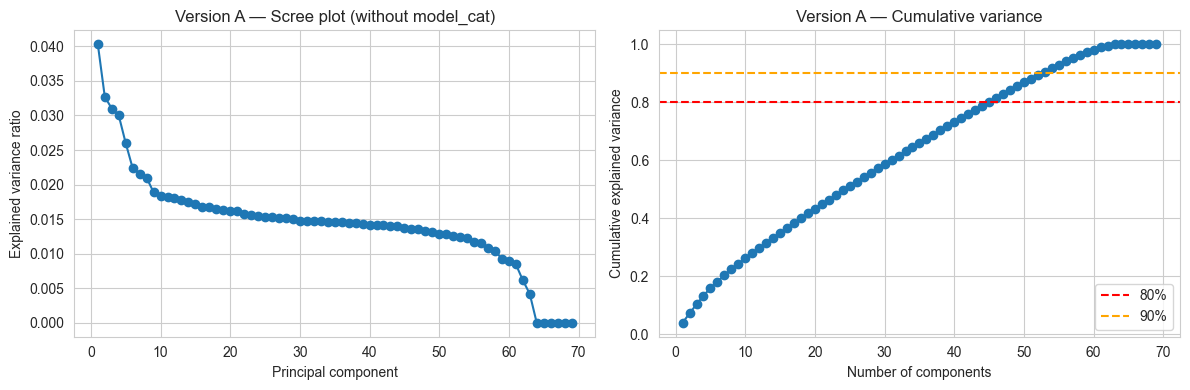

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Explained variance ratio per component
axes[0].plot(np.arange(1, len(pca_A.explained_variance_ratio_) + 1),
             pca_A.explained_variance_ratio_, marker="o")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Version A — Scree plot (without model_cat)")

# Cumulative explained variance
axes[1].plot(np.arange(1, len(pca_A.explained_variance_ratio_) + 1),
             np.cumsum(pca_A.explained_variance_ratio_), marker="o")
axes[1].axhline(0.8, color="red", linestyle="--", label="80%")
axes[1].axhline(0.9, color="orange", linestyle="--", label="90%")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_title("Version A — Cumulative variance")
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
# How many components to reach 80% / 90% variance?
cum_A = np.cumsum(pca_A.explained_variance_ratio_)
print(f"Version A — components for 80% variance: {(cum_A < 0.8).sum() + 1}")
print(f"Version A — components for 90% variance: {(cum_A < 0.9).sum() + 1}")
print(f"Version A — PC1 explains: {pca_A.explained_variance_ratio_[0]:.3%}")
print(f"Version A — PC1+PC2 explain: {pca_A.explained_variance_ratio_[:2].sum():.3%}")

Version A — components for 80% variance: 45
Version A — components for 90% variance: 53
Version A — PC1 explains: 4.029%
Version A — PC1+PC2 explain: 7.298%


### 4b. Loadings — Version A

For each of the top components, show the features with the largest absolute loading. This is how you interpret what each PC "means".

In [10]:
def top_loadings(pca, feature_names, pc_index, n=10):
    """Return a DataFrame of the top-n features (by |loading|) for one PC."""
    loadings = pca.components_[pc_index]
    s = pd.Series(loadings, index=feature_names)
    s_sorted = s.reindex(s.abs().sort_values(ascending=False).index)
    return s_sorted.head(n).to_frame(f"PC{pc_index + 1} loading")

print("=== Version A: top loadings for PC1, PC2, PC3 ===\n")
for i in range(3):
    print(top_loadings(pca_A, features_A, i, n=10))
    print()

=== Version A: top loadings for PC1, PC2, PC3 ===

                            PC1 loading
drivetrain_cat_2WD             0.420923
drivetrain_cat_4WD            -0.420923
year                          -0.369257
mileage                        0.321920
one_owner                     -0.242495
interior_color_Black          -0.228355
interior_color_Gray            0.224787
transmission_cat_manual        0.175456
transmission_cat_automatic    -0.175456
accidents_or_damage            0.170984

                            PC2 loading
fuel_type_cat_gasoline         0.440688
transmission_cat_manual        0.408398
transmission_cat_automatic    -0.408398
interior_color_Black           0.269652
fuel_type_cat_hybrid          -0.227986
fuel_type_cat_diesel          -0.216132
fuel_type_cat_e85             -0.199743
fuel_type_cat_electric        -0.195870
interior_color_Gray           -0.175362
manufacturer_cat_Tesla        -0.154036

                            PC3 loading
year                       

### 4c. PC1 vs PC2 scatter — Version A

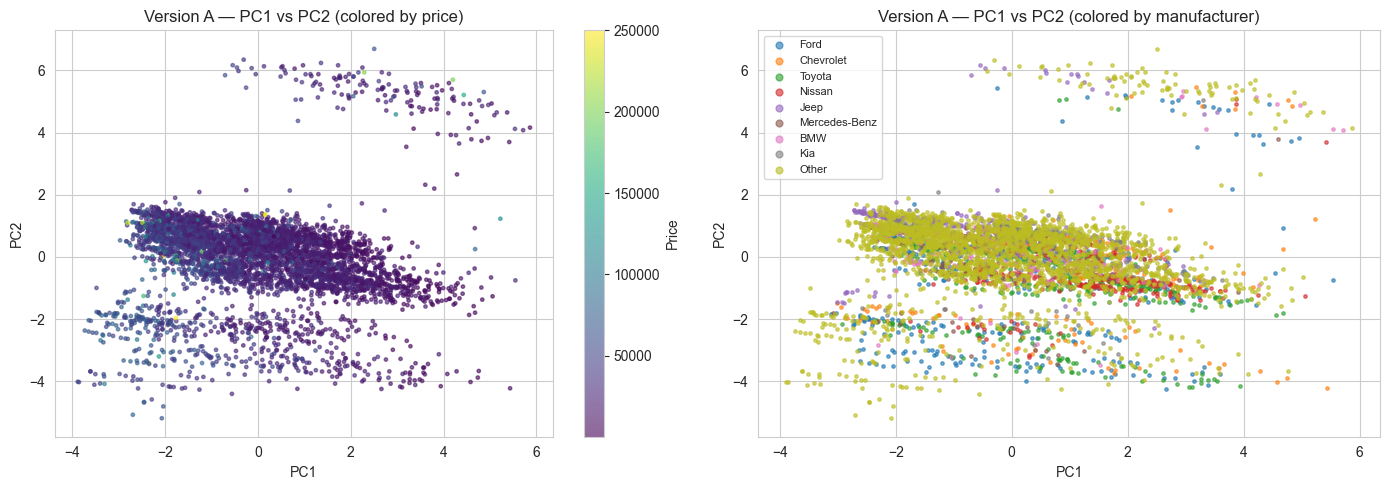

In [11]:
# Plot a sample to keep rendering fast (643k points is too many)
SAMPLE = 5000
idx = np.random.choice(len(scores_A), size=min(SAMPLE, len(scores_A)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Colored by price
sc0 = axes[0].scatter(scores_A[idx, 0], scores_A[idx, 1], c=y[idx],
                      cmap="viridis", s=6, alpha=0.6)
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("Version A — PC1 vs PC2 (colored by price)")
plt.colorbar(sc0, ax=axes[0], label="Price")

# Colored by manufacturer (top 8 manufacturers, rest grouped)
top_mfrs = df["manufacturer_cat"].value_counts().head(8).index
mfr_label = df["manufacturer_cat"].where(df["manufacturer_cat"].isin(top_mfrs), "Other")
for mfr in list(top_mfrs) + ["Other"]:
    mask = (mfr_label.iloc[idx].values == mfr)
    axes[1].scatter(scores_A[idx][mask, 0], scores_A[idx][mask, 1],
                    s=6, alpha=0.6, label=mfr)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("Version A — PC1 vs PC2 (colored by manufacturer)")
axes[1].legend(markerscale=2, fontsize=8, loc="best")

plt.tight_layout()
plt.show()

## 5. Version B — PCA **with** `model_cat`

Feature matrix: 4 numeric + ~734 one-hot columns. This is the high-cardinality version.

**Heads up**: this fits a PCA on a 643k × ~734 matrix. On a typical laptop expect a couple of minutes. If it's too slow, you can:
- Sample the dataframe first (e.g., `df.sample(100_000)`)
- Use `PCA(n_components=20, svd_solver="randomized")` to skip the full decomposition
- Use `sklearn.decomposition.TruncatedSVD` on a sparse one-hot representation

In [12]:
pca_B, scores_B, features_B, X_B = build_and_fit_pca(
    df,
    numeric_cols=numeric_cols,
    categorical_cols=categorical_cols_with_model,
    n_components=50,  # cap components for speed — we only need the top ones anyway
)

print("Design matrix shape:", X_B.shape)
print("Number of components fit:", pca_B.n_components_)

Design matrix shape: (642445, 738)
Number of components fit: 50


### 5a. Scree plot — Version B

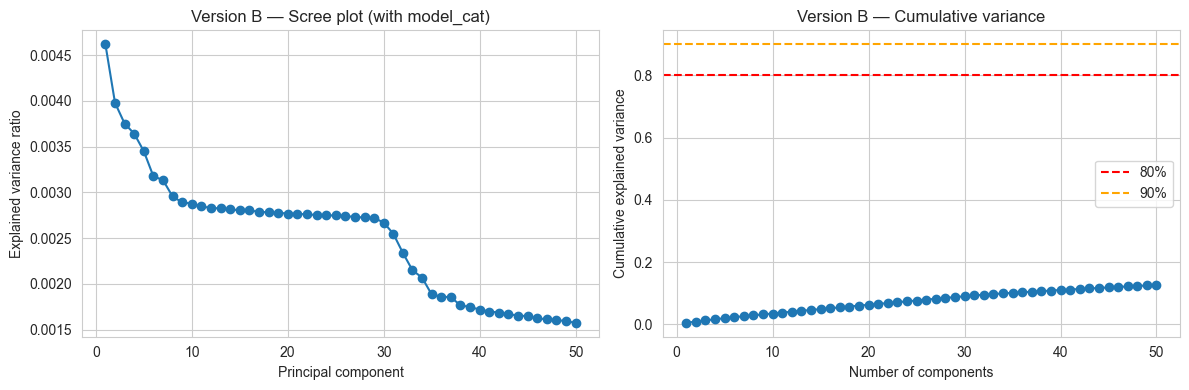

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(np.arange(1, len(pca_B.explained_variance_ratio_) + 1),
             pca_B.explained_variance_ratio_, marker="o")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Version B — Scree plot (with model_cat)")

axes[1].plot(np.arange(1, len(pca_B.explained_variance_ratio_) + 1),
             np.cumsum(pca_B.explained_variance_ratio_), marker="o")
axes[1].axhline(0.8, color="red", linestyle="--", label="80%")
axes[1].axhline(0.9, color="orange", linestyle="--", label="90%")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_title("Version B — Cumulative variance")
axes[1].legend()

plt.tight_layout()
plt.show()

In [14]:
cum_B = np.cumsum(pca_B.explained_variance_ratio_)
print(f"Version B — PC1 explains: {pca_B.explained_variance_ratio_[0]:.3%}")
print(f"Version B — PC1+PC2 explain: {pca_B.explained_variance_ratio_[:2].sum():.3%}")
print(f"Version B — top 50 components explain: {cum_B[-1]:.3%}")
print("(Note: we only computed 50 components for speed; the full decomposition would have ~738.)")

Version B — PC1 explains: 0.462%
Version B — PC1+PC2 explain: 0.860%
Version B — top 50 components explain: 12.624%
(Note: we only computed 50 components for speed; the full decomposition would have ~738.)


### 5b. Loadings — Version B

Watch for sparse loadings dominated by single `model_cat_*` dummies — that's the rare-category artifact problem.

In [15]:
print("=== Version B: top loadings for PC1, PC2, PC3 ===\n")
for i in range(3):
    print(top_loadings(pca_B, features_B, i, n=10))
    print()

=== Version B: top loadings for PC1, PC2, PC3 ===

                         PC1 loading
drivetrain_cat_2WD          0.416815
drivetrain_cat_4WD         -0.416815
year                       -0.248267
mileage                     0.206178
interior_color_Gray         0.204270
interior_color_Black       -0.180064
fuel_type_cat_diesel       -0.155332
one_owner                  -0.147737
manufacturer_cat_Nissan     0.142054
manufacturer_cat_RAM       -0.119933

                            PC2 loading
fuel_type_cat_gasoline         0.449951
fuel_type_cat_electric        -0.342889
manufacturer_cat_Tesla        -0.304558
model_cat_Model               -0.304485
fuel_type_cat_hybrid          -0.198242
fuel_type_cat_diesel          -0.197945
transmission_cat_manual        0.165796
transmission_cat_automatic    -0.165796
manufacturer_cat_Subaru        0.150152
fuel_type_cat_e85             -0.142353

                            PC3 loading
interior_color_Black           0.364559
transmission_cat_man

### 5c. PC1 vs PC2 scatter — Version B

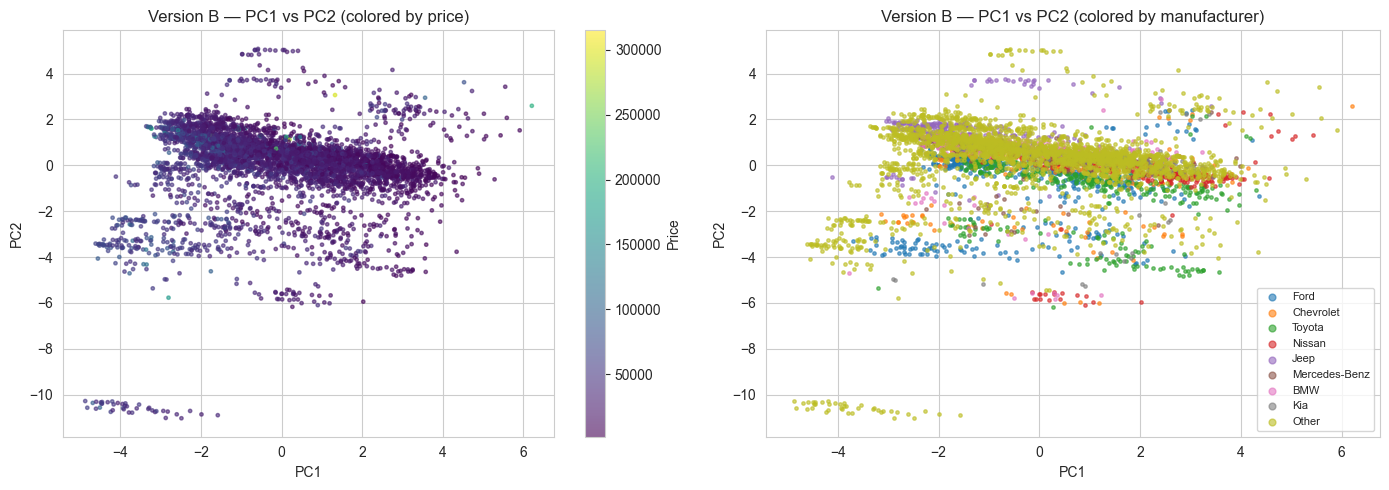

In [16]:
idx_B = np.random.choice(len(scores_B), size=min(SAMPLE, len(scores_B)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc0 = axes[0].scatter(scores_B[idx_B, 0], scores_B[idx_B, 1], c=y[idx_B],
                      cmap="viridis", s=6, alpha=0.6)
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("Version B — PC1 vs PC2 (colored by price)")
plt.colorbar(sc0, ax=axes[0], label="Price")

for mfr in list(top_mfrs) + ["Other"]:
    mask = (mfr_label.iloc[idx_B].values == mfr)
    axes[1].scatter(scores_B[idx_B][mask, 0], scores_B[idx_B][mask, 1],
                    s=6, alpha=0.6, label=mfr)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("Version B — PC1 vs PC2 (colored by manufacturer)")
axes[1].legend(markerscale=2, fontsize=8, loc="best")

plt.tight_layout()
plt.show()

## 6. Side-by-side comparison

The clearest visual diagnostic is overlaying the two scree plots. If Version B's curve is much flatter than Version A's, that confirms variance is being diluted across many sparse components — a sign that including `model_cat` is hurting the dimensionality reduction.

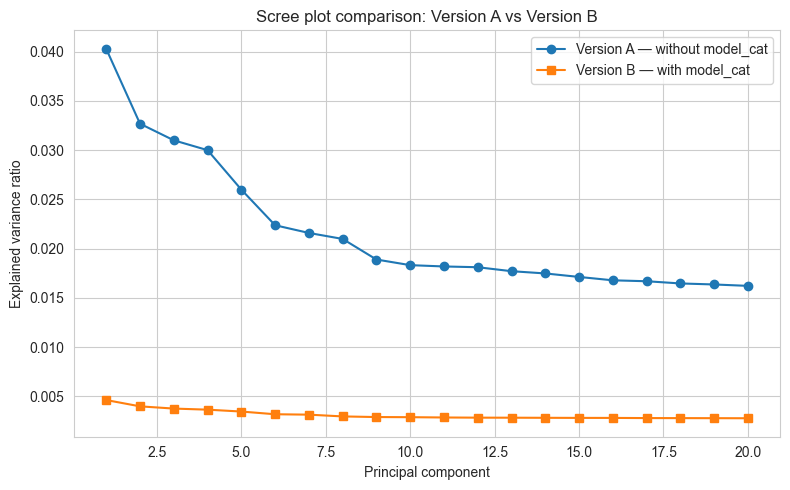

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))

n_show = min(20, len(pca_A.explained_variance_ratio_), len(pca_B.explained_variance_ratio_))

ax.plot(np.arange(1, n_show + 1), pca_A.explained_variance_ratio_[:n_show],
        marker="o", label="Version A — without model_cat")
ax.plot(np.arange(1, n_show + 1), pca_B.explained_variance_ratio_[:n_show],
        marker="s", label="Version B — with model_cat")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("Scree plot comparison: Version A vs Version B")
ax.legend()

plt.tight_layout()
plt.show()

In [18]:
# Numeric comparison table
comparison = pd.DataFrame({
    "Metric": [
        "Design matrix columns",
        "PC1 explained variance",
        "PC1 + PC2 explained variance",
        "PC1 + PC2 + PC3 explained variance",
        "Components to reach 80% variance",
    ],
    "Version A (no model_cat)": [
        X_A.shape[1],
        f"{pca_A.explained_variance_ratio_[0]:.3%}",
        f"{pca_A.explained_variance_ratio_[:2].sum():.3%}",
        f"{pca_A.explained_variance_ratio_[:3].sum():.3%}",
        (cum_A < 0.8).sum() + 1,
    ],
    "Version B (with model_cat)": [
        X_B.shape[1],
        f"{pca_B.explained_variance_ratio_[0]:.3%}",
        f"{pca_B.explained_variance_ratio_[:2].sum():.3%}",
        f"{pca_B.explained_variance_ratio_[:3].sum():.3%}",
        (cum_B < 0.8).sum() + 1 if (cum_B >= 0.8).any() else f">{len(cum_B)} (not reached in top 50)",
    ],
})
comparison

,Metric,Version A (no model_cat),Version B (with model_cat)
0,Design matrix columns,69,738
1,PC1 explained variance,4.029%,0.462%
2,PC1 + PC2 explained variance,7.298%,0.860%
3,PC1 + PC2 + PC3 explained variance,10.399%,1.235%
4,Components to reach 80% variance,45,>50 (not reached in top 50)


## 7. Discussion (fill in based on your output)

After running the notebook, you should be able to answer:

1. **Does Version A have a clearer "elbow" in the scree plot than Version B?** If yes, that's evidence that the lower-cardinality version is doing real dimensionality reduction.
2. **In Version A, can you give each of the top 2–3 PCs a meaningful name** (like "age/wear axis" or "luxury vs. economy")? Look at the loadings table.
3. **In Version B, do the top PCs have sparse loadings dominated by `model_cat_*` dummies?** If so, that's the rare-category artifact behavior we predicted.
4. **How much extra variance does Version B "explain" with its extra ~670 columns?** Often the answer is "surprisingly little, and most of what it does add is noise."

The version you ultimately use in your writeup should be the one whose principal components you can interpret and defend in plain English.